# DP Plots

AUC and trainer return vs the privacy budget for several mechanisms at one n, on a log scaled axis

In [1]:
import os
import numpy as np
from scipy import stats
import pandas as pd
from matplotlib import pyplot as plt


def metric_by_epsilon(name, n, k=1, metric="AUC"):
    """Mean and 95% CI half-width of a metric per epsilon (inf = non-private) from data/tables/hyperparam_results_{name}.csv."""
    d = pd.read_csv(f"../data/tables/hyperparam_results_{name}.csv")
    d = d[(d["N. Trajectories"] == n) & (d["Ensemble k"] == k)]
    g = d.groupby(d["Ensemble epsilon"].fillna(np.inf))[metric]
    ci = g.agg(lambda x: stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)))
    return pd.DataFrame({"mean": g.mean(), "ci": ci, "runs": g.size()})


def _plot_metric(ax, t, color, reference, reference_label, ylim, ylabel):
    """One metric against epsilon on ax, with its CI band, non-private line, and reference line."""
    private = t[np.isfinite(t.index)]
    ax.plot(private.index, private["mean"], color=color, marker="o", markersize=4)
    ax.fill_between(private.index, private["mean"] - private["ci"], private["mean"] + private["ci"],
                    color=color, alpha=0.2, linewidth=0)
    if np.inf in t.index:
        ax.axhline(t.loc[np.inf, "mean"], color="black", linestyle="--", linewidth=1, label=r"No noise ($\varepsilon = \infty$)")
    ax.axhline(reference, color="gray", linestyle="--", linewidth=1, label=reference_label)
    ax.set_xscale("log")
    ax.set_ylim(ylim)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best", fontsize=8)


def stacked_auc_vs_epsilon(panels, n, random_return, title=None, filename=None,
                           auc_ylim=(0.45, 1.0), return_ylim=(0.76, 0.85)):
    """Produces the final stacked plot of AUC vs epsilon for an arbitrary number of panels."""
    fig, axes = plt.subplots(len(panels), 2, figsize=(11, 2.8 * len(panels)), sharex=True, squeeze=False)
    for row, (label, name, k) in zip(axes, panels):
        _plot_metric(row[0], metric_by_epsilon(name, n, k, "AUC"), "red", 0.5, "Random guess", auc_ylim, "AUC")
        _plot_metric(row[1], metric_by_epsilon(name, n, k, "Trainer Mean Reward"), "green",
                     random_return, "Random policy", return_ylim, "Return")
        row[0].set_title(f"{label}: AUC")
        row[1].set_title(f"{label}: return")
    for ax in axes[-1]:
        ax.set_xlabel(r"Privacy budget $\varepsilon$")
    if title is not None:
        fig.suptitle(title)
    fig.tight_layout()
    if filename is not None:
        os.makedirs("../data/plots/auc_vs_epsilon", exist_ok=True)
        fig.savefig(f"../data/plots/auc_vs_epsilon/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

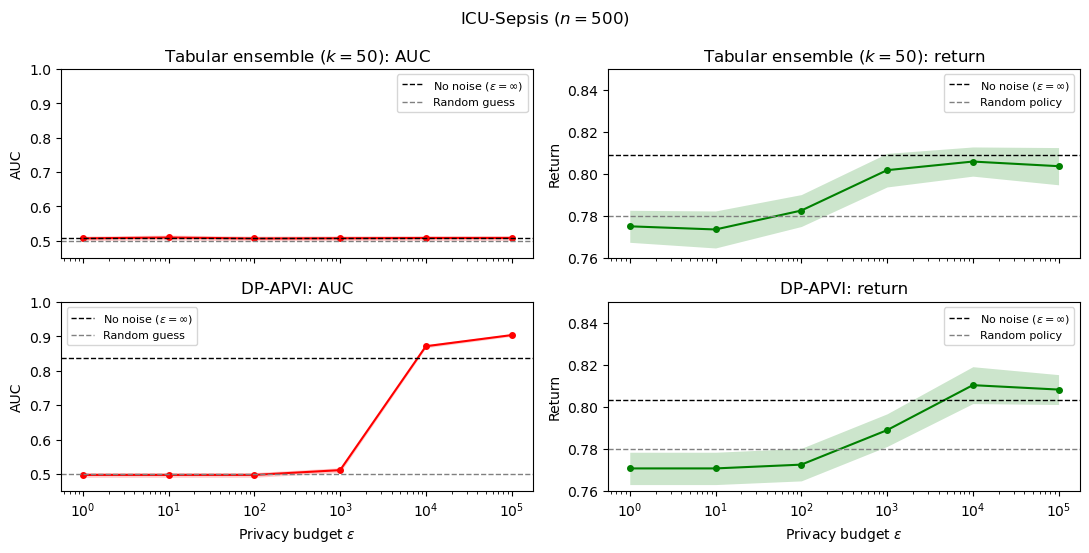

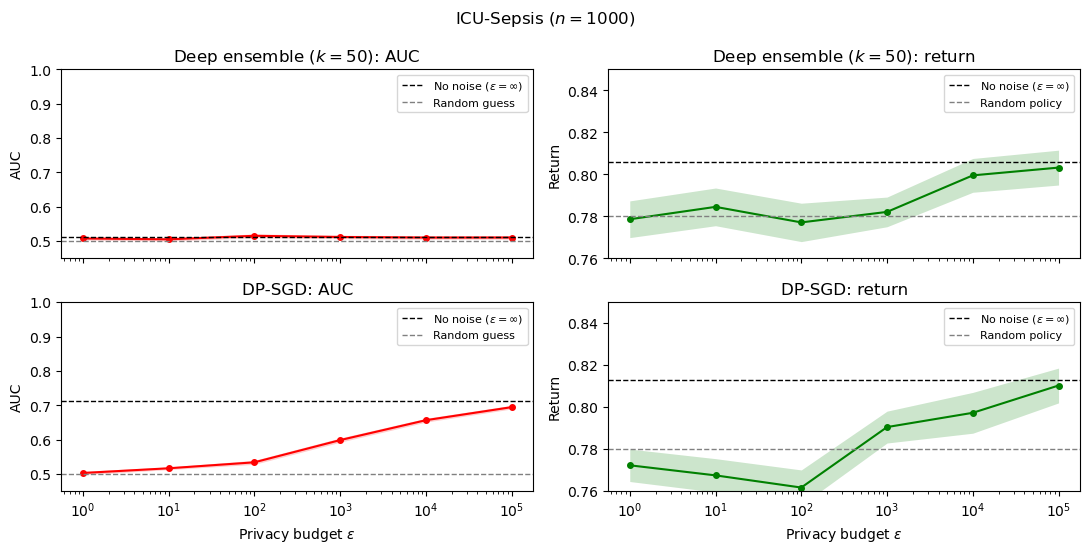

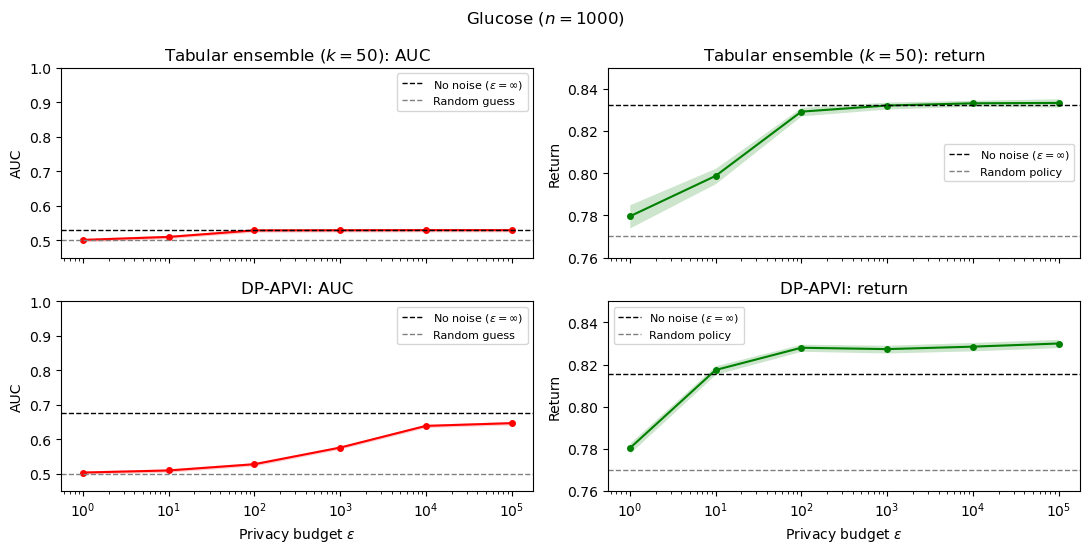

In [2]:
N, K = 500, 50  # every ensemble uses k = 50

stacked_auc_vs_epsilon(
    [(f"Tabular ensemble ($k = {K}$)", "sepsis_tabular_ensemble", K), ("DP-APVI", "sepsis_dpapvi", 1)],
    n=N, random_return=0.78, title=f"ICU-Sepsis ($n = {N}$)", filename=f"sepsis_ensemble_vs_dpapvi_n{N}.png",
)
N = 1000
stacked_auc_vs_epsilon(
    [(f"Deep ensemble ($k = {K}$)", "sepsis_cql_ensemble", K), ("DP-SGD", "sepsis_dpsgd", 1)],
    n=N, random_return=0.78, title=f"ICU-Sepsis ($n = {N}$)", filename=f"sepsis_ensemble_vs_dpsgd_n{N}.png",
)
stacked_auc_vs_epsilon(
    [(f"Tabular ensemble ($k = {K}$)", "glucose_tabular_ensemble", K), ("DP-APVI", "glucose_dpapvi", 1)],
    n=N, random_return=0.77, title=f"Glucose ($n = {N}$)", filename=f"glucose_ensemble_vs_dpapvi_n{N}.png",
)
